# Training and validating a PCA + kNN emitter classifier

Day-1, chamber, cold, chirp pulses from adc0 only. Pulses are flattened, standardised, projected onto principal components and classified with kNN.

In [1]:
import os
# Keep BLAS single-threaded (avoids OpenBLAS thread problems); must run before numpy is first imported
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

import torch
import numpy as np

torch.set_num_threads(1)

seed = 42
generator = torch.Generator().manual_seed(seed)
np.random.seed(seed)

## Load the data

In [2]:
# import sys; sys.path.append("..")     # uncomment if this notebook is not in the project root
from dataloaders.dataloader import SimplePulseDataset

ds = SimplePulseDataset(
    hdf5_dir="./data",
    load_to_memory=True,
    max_pulses_per_emitter=1000,
    adc_names=["adc0"],
    adc_mode="single",
    day_filter=["day1"],
    environment_filter=["chamber"],
    temp_filter=["cold"],
    blade_filter=None,
    waveform_filter=["chirp"],
    return_pdw=True,
)

Dataset: 12000 groups x 1 ADCs (0 unmatched, 2 below 31 dB dropped)
Loading all data to memory...
Loaded 12000 entries to memory


## Emitter classes and train/test split

In [3]:
from torch.utils.data import random_split

# Build emitter vocabulary directly from the filtered dataset
emitter_idx = {
    emitter: i
    for i, emitter in enumerate(sorted({entry["labels"]["emitter"] for entry in ds.pulse_index}))
}
idx_to_label = {v: k for k, v in emitter_idx.items()}
print(f"Emitter classes ({len(emitter_idx)}): {list(emitter_idx.keys())}")

train_size = int(0.8 * len(ds))
test_size = len(ds) - train_size
train_base, test_base = random_split(ds, [train_size, test_size], generator=generator)

Emitter classes (12): ['blade1', 'blade10', 'blade11', 'blade12', 'blade2', 'blade3', 'blade4', 'blade5', 'blade6', 'blade7', 'blade8', 'blade9']


## Training data

In [4]:
from dataloaders.dataloader import AugmentedPulseDataset
from torch.utils.data import DataLoader

train_SNRs = [30, 25, 20, 15, 10, 5, 0]
test_SNRs = [30, 25, 20, 15, 10, 5, 0]

train_dataset = AugmentedPulseDataset(
    base_dataset=train_base,
    target_snrs_db=train_SNRs,
    add_magnitude=True,
    normalise=True,
    return_pdw=False,
    mode="single",
    flatten_pulse=True
)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [5]:
def extract_features(loader):
    """Pulls flattened (batch, D) feature vectors + emitter labels out of a
    DataLoader built on an AugmentedPulseDataset with flatten_pulse=True."""
    X_list, y_list = [], []
    for signals, labels in loader:
        X_list.append(signals.numpy())
        y_list.extend(labels['emitter'])
    X = np.concatenate(X_list, axis=0)
    y = np.array([emitter_idx[l] for l in y_list])
    return X, y

## Fit

In [6]:
import time
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from threadpoolctl import threadpool_limits

# PCA/kNN hyperparameters
N_PCA_COMPONENTS = 50
N_NEIGHBORS = 5

start_training = time.time()

print("Extracting training features...")
X_train_raw, y_train = extract_features(train_loader)
print(f"  X_train {X_train_raw.shape} = {X_train_raw.nbytes / 1e9:.2f} GB")

print("Fitting StandardScaler + PCA + kNN...")
with threadpool_limits(limits=1, user_api="blas"):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_raw)

    pca = PCA(n_components=N_PCA_COMPONENTS, random_state=seed)
    X_train_pca = pca.fit_transform(X_train_scaled)
    print(f"  Explained variance (first {N_PCA_COMPONENTS} components): "
          f"{pca.explained_variance_ratio_.sum():.3f}")

    knn = KNeighborsClassifier(n_neighbors=N_NEIGHBORS)
    knn.fit(X_train_pca, y_train)

fit_duration = time.time() - start_training
print(f"Fit duration: {fit_duration:.2f}s")

Extracting training features...
  X_train (67200, 24576) = 6.61 GB
Fitting StandardScaler + PCA + kNN...
  Explained variance (first 50 components): 0.646
Fit duration: 73.49s


## Plotting helpers

In [7]:
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, matthews_corrcoef, f1_score

def plot_confusion_matrix(y_true, y_pred, label):
    mcc = matthews_corrcoef(y_true, y_pred)
    fone = f1_score(y_true, y_pred, average="macro")
    print(f"  [{label}] MCC: {mcc:.4f} | F1 (macro): {fone:.4f}")

    class_ids = sorted(idx_to_label.keys())
    display_labels = [idx_to_label[i] for i in class_ids]
    cm_norm = confusion_matrix(y_true, y_pred, normalize="true", labels=class_ids)

    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=display_labels).plot(
        cmap="viridis", ax=ax, xticks_rotation=45, values_format=".2f"
    )
    ax.set_title(f"PCA+kNN Confusion Matrix — {label}", fontsize=14)
    ax.set_xlabel("Predicted Label", fontsize=13)
    ax.set_ylabel("True Label", fontsize=13)
    plt.tight_layout()
    plt.show()

    return mcc, fone


def plot_f1_vs_snr(f1_scores, snrs):
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(snrs, f1_scores, marker="o", color="steelblue", linewidth=2, label="PCA + kNN")
    ax.set_xticks(snrs)
    ax.set_xlabel("SNR (dB)", fontsize=13)
    ax.set_ylabel("F1 (macro)", fontsize=13)
    ax.set_ylim(0, 1.05)
    ax.grid(True, alpha=0.3)
    ax.legend()
    ax.set_title("PCA + kNN — F1 vs SNR", fontsize=14)
    plt.tight_layout()
    plt.show()

## Save the model

In [9]:
import joblib

run_name = "day1_chamber_cold_adc0_chirp_pca"
run_dir = os.path.join("runs", run_name)
os.makedirs(run_dir, exist_ok=True)

model_path = os.path.join(run_dir, f"{run_name}_model.joblib")
joblib.dump({"scaler": scaler, "pca": pca, "knn": knn, "emitter_idx": emitter_idx}, model_path)
print(f"Saved fitted scaler+PCA+kNN: {model_path}")

Saved fitted scaler+PCA+kNN: runs/day1_chamber_cold_adc0_chirp_pca/day1_chamber_cold_adc0_chirp_pca_model.joblib


## Reload the model

The fitted objects are deleted from memory and loaded back from the file, so the evaluation below can only use the reloaded model.

In [10]:
del scaler, pca, knn, emitter_idx, idx_to_label

bundle = joblib.load(model_path)
scaler, pca, knn, emitter_idx = bundle["scaler"], bundle["pca"], bundle["knn"], bundle["emitter_idx"]
idx_to_label = {v: k for k, v in emitter_idx.items()}
print(f"Reloaded scaler+PCA+kNN from {model_path}")

Reloaded scaler+PCA+kNN from runs/day1_chamber_cold_adc0_chirp_pca/day1_chamber_cold_adc0_chirp_pca_model.joblib


## Evaluate across the SNR sweep

Evaluating: 30dB
  [30dB] MCC: 0.5157 | F1 (macro): 0.5610


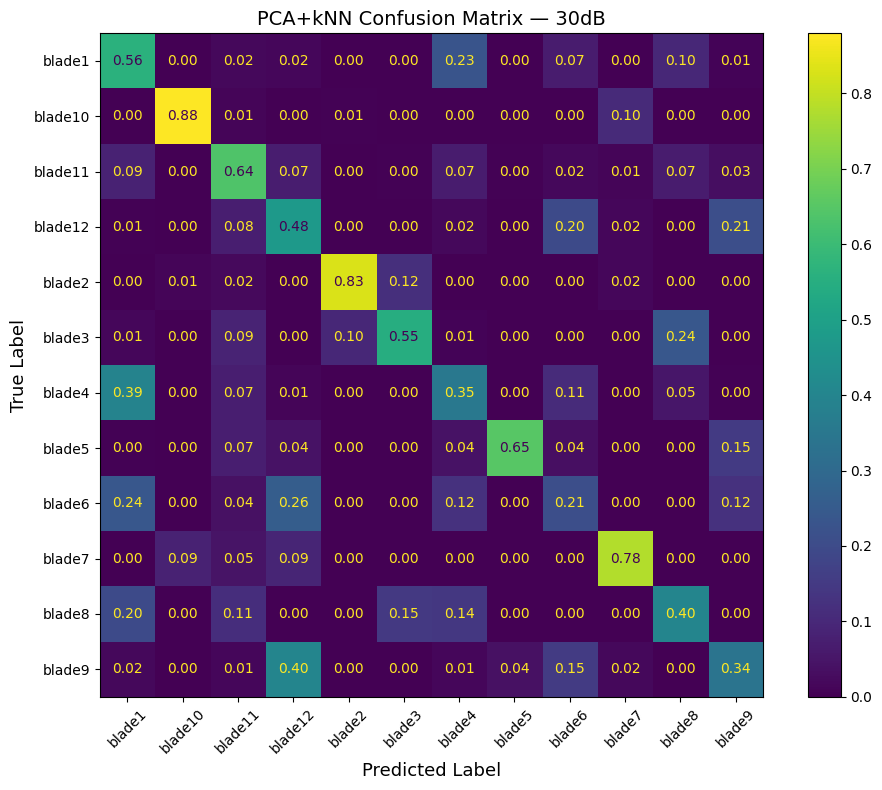

Evaluating: 25dB
  [25dB] MCC: 0.5052 | F1 (macro): 0.5538


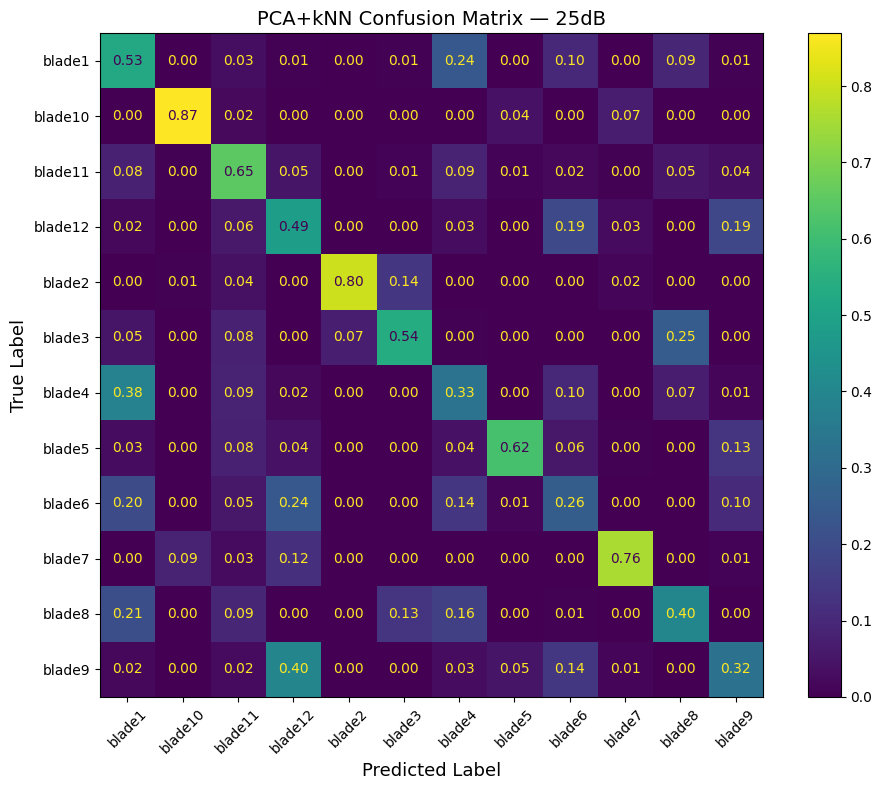

Evaluating: 20dB
  [20dB] MCC: 0.4357 | F1 (macro): 0.4922


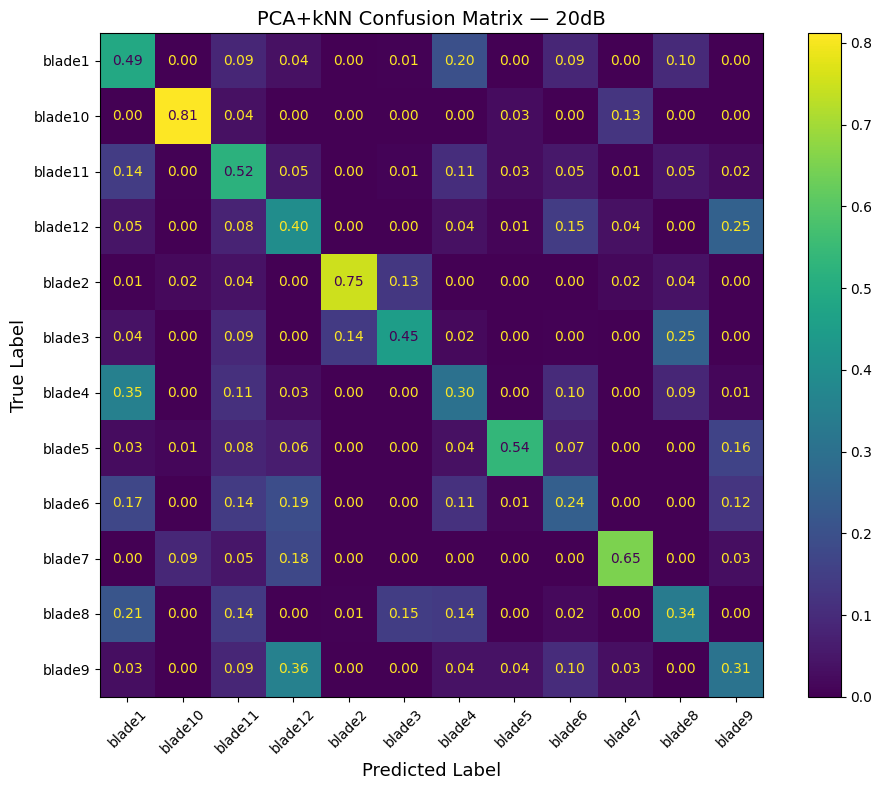

Evaluating: 15dB
  [15dB] MCC: 0.3724 | F1 (macro): 0.4340


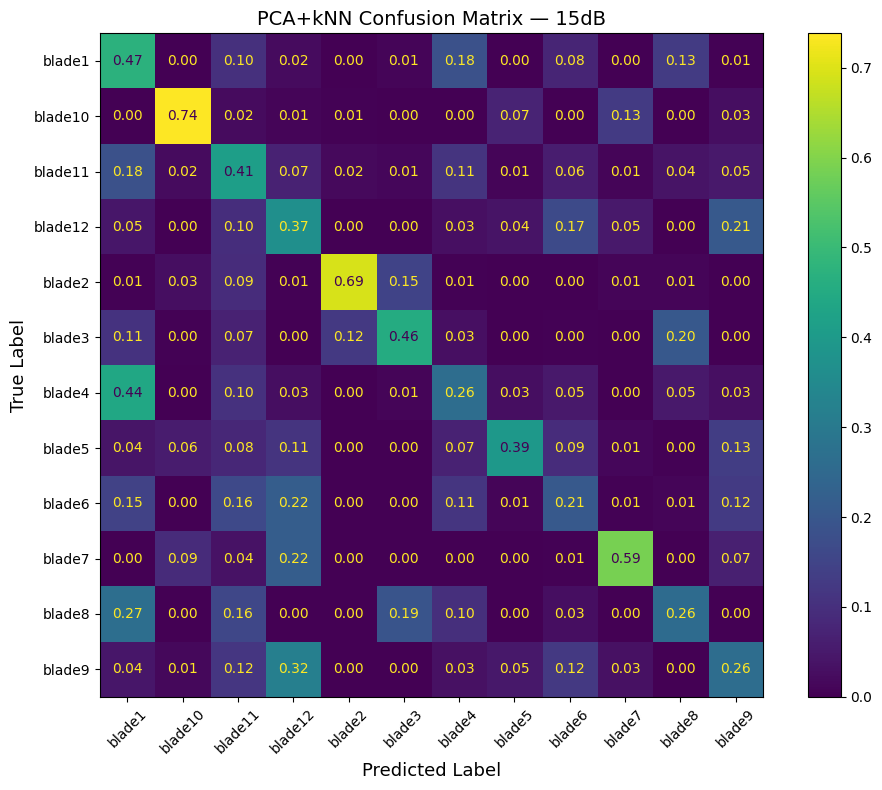

Evaluating: 10dB
  [10dB] MCC: 0.2679 | F1 (macro): 0.3328


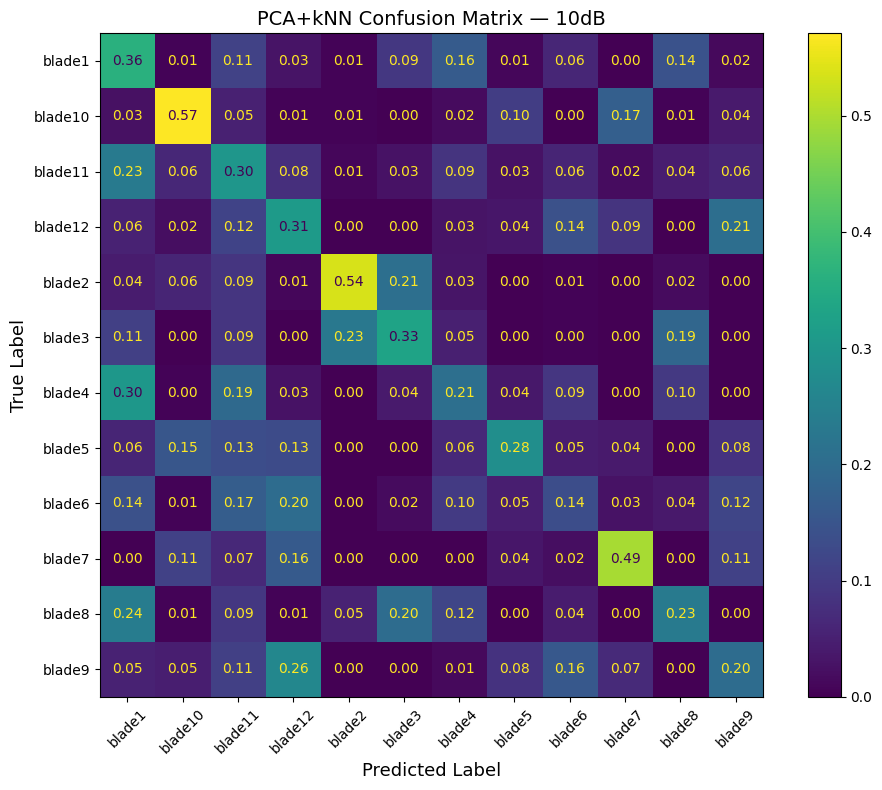

Evaluating: 5dB
  [5dB] MCC: 0.1551 | F1 (macro): 0.2248


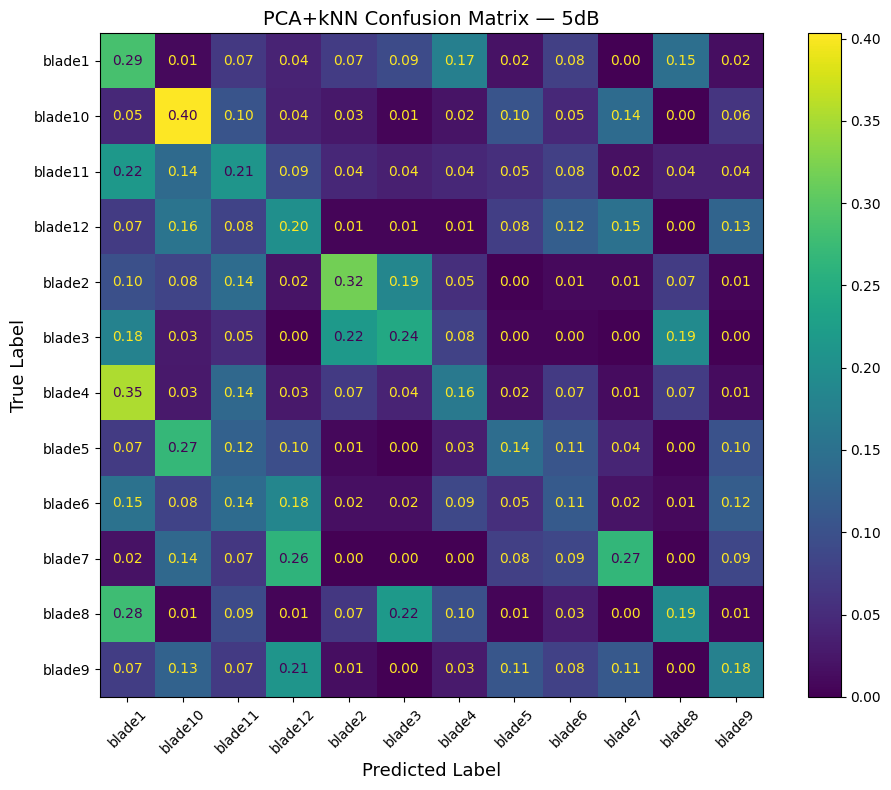

Evaluating: 0dB
  [0dB] MCC: 0.1147 | F1 (macro): 0.1841


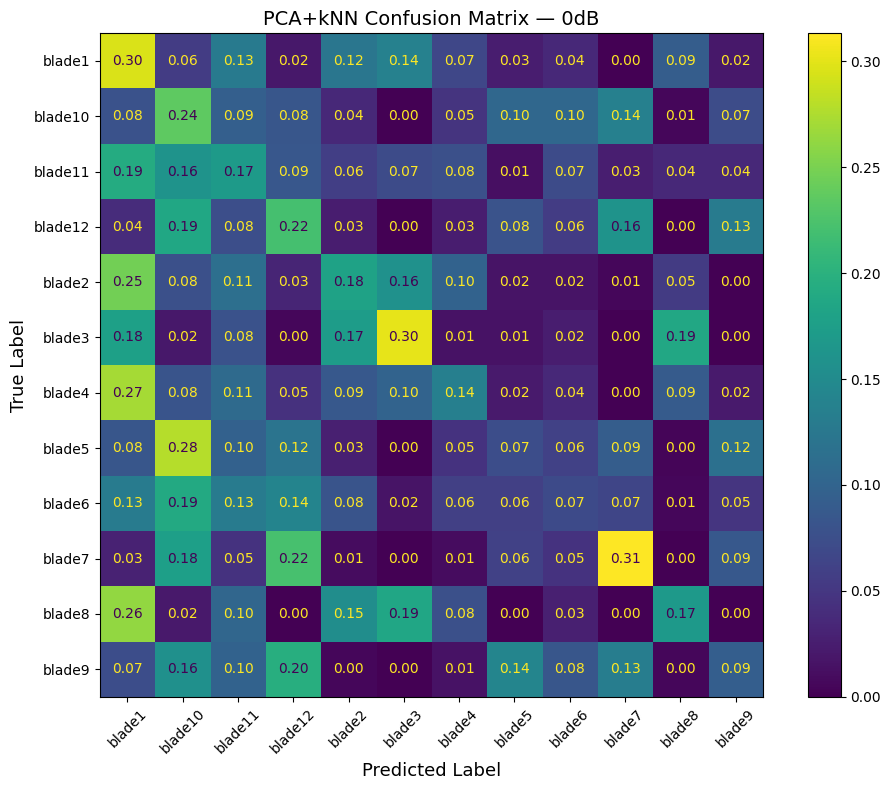

In [11]:
f1_scores = []
for snr in test_SNRs:
    label = f"{snr}dB"
    print(f"Evaluating: {label}")

    eval_dataset = AugmentedPulseDataset(
        base_dataset=test_base,
        target_snrs_db=[snr],
        add_magnitude=True,
        normalise=True,
        return_pdw=False,
        mode="single",
        flatten_pulse=True
    )
    eval_loader = DataLoader(eval_dataset, batch_size=64, shuffle=False)

    X_eval_raw, y_eval = extract_features(eval_loader)
    X_eval_scaled = scaler.transform(X_eval_raw)
    X_eval_pca = pca.transform(X_eval_scaled)
    y_pred = knn.predict(X_eval_pca)

    _, fone = plot_confusion_matrix(y_eval, y_pred, label)
    f1_scores.append(fone)

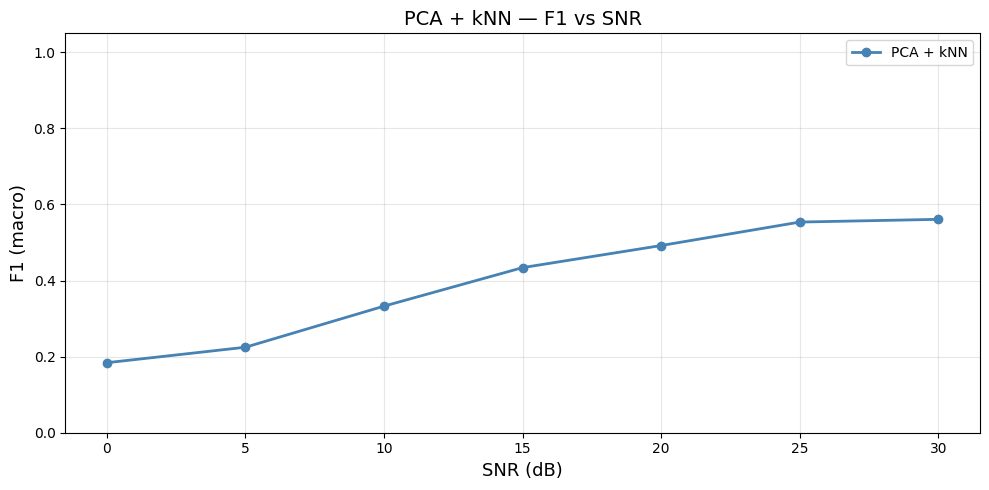

In [12]:
plot_f1_vs_snr(f1_scores, test_SNRs)